# 06 Biodiversity and ecosystem health

**Questions**
1. Which African countries show the greatest biodiversity pressure?
2. Is forest loss associated with worsening species status?
3. Does protected-area coverage correspond with better outcomes?

**What I expect going in**
- **H1** The Red List Index has declined (species moving closer to extinction) in most African countries since 2000.
- **H2** Countries with higher relative tree cover loss saw larger Red List Index declines.

**Read before interpreting:** the Red List Index runs from 1 (no species threatened) to 0 (all extinct) and is driven by comprehensively assessed groups (birds, mammals, amphibians, corals, cycads). Threatened species counts are a one-year snapshot and grow with species richness, so they rank species-rich countries high for reasons other than pressure. Protected-area share measures legal designation, not how well areas are managed, and areas are often designated where threats are already high, so a simple comparison cannot show whether protection works.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.dpi": 110, "font.size": 9})
BLUE, GREY, RED, GREEN = "#1f4e79", "#7f7f7f", "#c00000", "#2f6f4f"

DATA = Path("data")
OUT = Path("outputs") / "06 biodiversity"
OUT.mkdir(parents=True, exist_ok=True)
for f in OUT.glob("*"):
    f.unlink()          # start each run with an empty outputs folder

obs = pd.read_csv(DATA / "observations.csv", dtype={"flag": str})        # long: iso3, year, indicator_id, value, source, flag
panel = pd.read_csv(DATA / "panel.csv")                # wide: one row per country-year
ind = pd.read_csv(DATA / "indicators.csv").set_index("indicator_id")
cty = pd.read_csv(DATA / "countries.csv").set_index("iso3")
AFRICA = cty.index[cty["group"] == "Africa"].tolist()
name = cty["country_name"].to_dict()
af = obs[obs["iso3"].isin(AFRICA)]
afp = panel[panel["iso3"].isin(AFRICA)]


def label(i):
    return f"{ind.at[i, 'indicator_name']} ({ind.at[i, 'unit']})" if i in ind.index else i


def has(*ids):
    missing = [i for i in ids if i not in panel.columns]
    if missing:
        print("Not in the data, skipped:", ", ".join(missing))
    return not missing


def latest(i, frame=None, max_age=5):
    """Latest observed value per country. Values more than max_age years older than the
    newest year for that indicator are dropped so stale points do not enter rankings."""
    s = (frame if frame is not None else af)
    s = s[s["indicator_id"] == i].sort_values("year").groupby("iso3").tail(1)
    s = s[s["year"] >= s["year"].max() - max_age]
    return s.assign(country=s["iso3"].map(name)).sort_values("value", ascending=False)[["iso3", "country", "year", "value"]]


def change(i, base=(2000, 2002)):
    """Change from the 2000 to 2002 average (damps single-year noise) to the latest value.
    Percentage change only where the base is above the 10th percentile, so tiny bases
    do not produce meaningless growth rates."""
    s = af[af["indicator_id"] == i]
    b = s[s["year"].between(*base)].groupby("iso3")["value"].mean().rename("base")
    l = s.sort_values("year").groupby("iso3").tail(1).set_index("iso3")[["year", "value"]].rename(columns={"value": "latest", "year": "latest_year"})
    d = l.join(b, how="inner")
    d["abs_change"] = d["latest"] - d["base"]
    floor = d["base"].abs().quantile(0.10)
    d["pct_change"] = np.where(d["base"].abs() > floor, 100 * d["abs_change"] / d["base"].abs(), np.nan)
    d.insert(0, "country", d.index.map(name))
    return d.sort_values("abs_change", ascending=False)


def median_path(i, iso=None):
    """Africa median by year (only years where at least 10 countries report), or one economy's series."""
    if iso:
        s = obs[(obs["indicator_id"] == i) & (obs["iso3"] == iso)]
        return s.set_index("year")["value"].sort_index()
    s = af[af["indicator_id"] == i].groupby("year")["value"].agg(["median", "count"])
    return s.loc[s["count"] >= 10, "median"]


def barh(df, value, title, xlabel, path, n=15, color=BLUE):
    d = df.head(n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(d) + 1))
    ax.barh(d["country"], d[value], color=color)
    for y, (v, yr) in enumerate(zip(d[value], d.get("year", d.get("latest_year", [""] * len(d))))):
        ax.text(v, y, f" {v:,.2f} ({yr})" if yr != "" else f" {v:,.2f}", va="center", fontsize=7)
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel); ax.grid(axis="y", visible=False)
    fig.tight_layout(); fig.savefig(OUT / path, dpi=150); plt.show()


def save_excel(path, sheets):
    """Tables to Excel in house style: Tahoma 8, bold headers without fill, frozen header, no gridlines."""
    from openpyxl.styles import Font
    with pd.ExcelWriter(OUT / path, engine="openpyxl") as xl:
        for sheet, frame in sheets.items():
            frame.to_excel(xl, sheet_name=sheet[:31])
        for ws in xl.book.worksheets:
            ws.sheet_view.showGridLines = False
            ws.freeze_panes = "B2"
            for row in ws.iter_rows():
                for c in row:
                    c.font = Font(name="Tahoma", size=8, bold=(c.row == 1))
                    if isinstance(c.value, float):
                        c.number_format = "#,##0.00;(#,##0.00);-"
    return sorted(p.name for p in OUT.iterdir())

## 1. Red List Index: level and change (H1)

H1: Red List Index fell in 98% of 54 countries since 2000 to 2002


,country,value,latest_year,abs_change
iso3,,,,
MUS,Mauritius,0.460,2025,-0.066
SYC,Seychelles,0.560,2025,-0.064
STP,Sao Tome and Principe,0.719,2025,-0.039
MDG,Madagascar,0.724,2025,-0.054
COM,Comoros,0.759,2025,-0.049
MAR,Morocco,0.772,2025,-0.101
GNQ,Equatorial Guinea,0.783,2025,-0.035
TZA,Tanzania,0.802,2025,-0.041
DJI,Djibouti,0.823,2025,-0.029


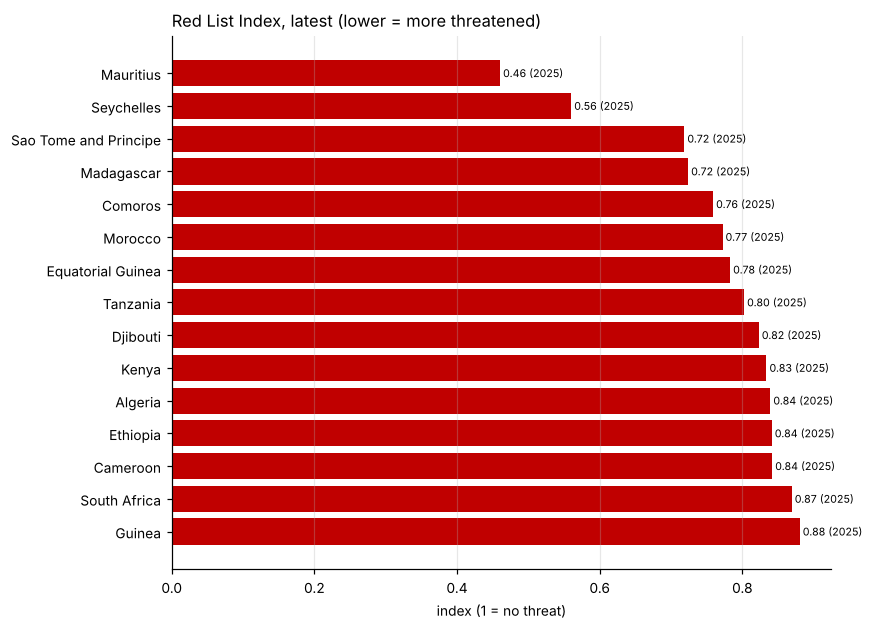

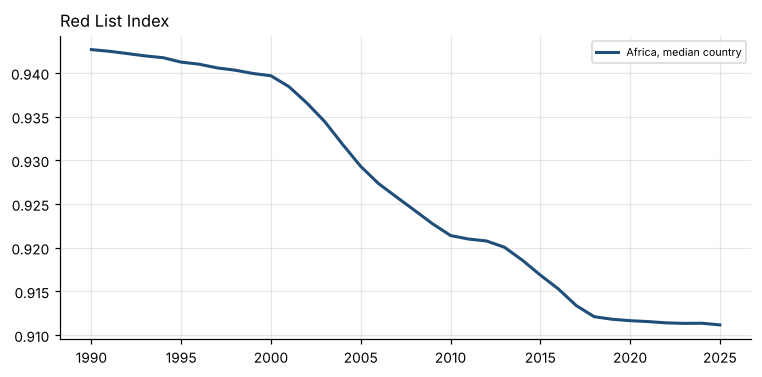

,country,latest_year,latest,base,abs_change,pct_change
iso3,,,,,,
MAR,Morocco,2025,0.772,0.873,-0.101,-11.555
MUS,Mauritius,2025,0.460,0.526,-0.066,NaN
SYC,Seychelles,2025,0.560,0.624,-0.064,NaN
LBY,Libya,2025,0.889,0.950,-0.062,-6.504
DZA,Algeria,2025,0.839,0.900,-0.061,-6.762
TUN,Tunisia,2025,0.881,0.938,-0.057,-6.106
MDG,Madagascar,2025,0.724,0.778,-0.054,NaN
MOZ,Mozambique,2025,0.888,0.941,-0.053,-5.622
COM,Comoros,2025,0.759,0.808,-0.049,NaN


In [2]:
if has("E08"):
    rli = change("E08")
    print(f"H1: Red List Index fell in {(rli['abs_change'] < 0).mean():.0%} of {len(rli)} countries since 2000 to 2002")
    worst = rli.sort_values("latest").rename(columns={"latest": "value"})
    display(worst.head(10)[["country", "value", "latest_year", "abs_change"]])
    barh(worst.assign(year=worst["latest_year"]), "value", "Red List Index, latest (lower = more threatened)", "index (1 = no threat)", "red list index lowest.png", color=RED)
    m, w = median_path("E08"), median_path("E08", "WLD")
    fig, ax = plt.subplots(figsize=(7, 3.5))
    ax.plot(m.index, m.values, color=BLUE, lw=2, label="Africa, median country")
    if len(w):
        ax.plot(w.index, w.values, "--", color=GREY, label="World")
    ax.set_title("Red List Index", loc="left"); ax.legend(fontsize=7)
    fig.tight_layout(); fig.savefig(OUT / "red list index trend.png", dpi=150); plt.show()
    display(rli.sort_values("abs_change").head(10))

**H1 supported almost everywhere: the Red List Index fell in 98% of African countries since 2000 to 2002.**

- The African median fell from 0.940 (2000) to 0.911 (2024).
- Island states have the most threatened species: Mauritius (0.46), Seychelles (0.56), Sao Tome and Principe (0.72), Madagascar (0.72) and Comoros (0.76).
- Morocco had the largest decline (-0.10), followed by Mauritius, Seychelles, Libya and Algeria.

## 2. Threatened species counts (snapshot)

In [3]:
th = [i for i in ("E01", "E02", "E03", "E04") if i in panel]
if th:
    snap = pd.concat({ind.at[i, "indicator_name"]: latest(i, max_age=50).set_index("iso3")["value"] for i in th}, axis=1)
    snap["total"] = snap.sum(axis=1, min_count=1)
    snap.insert(0, "country", snap.index.map(name))
    print("Single-year snapshot, not a trend. Raw counts favour species-rich countries.")
    display(snap.sort_values("total", ascending=False).head(12))

Single-year snapshot, not a trend. Raw counts favour species-rich countries.


,country,"Mammal species, threatened","Bird species, threatened","Fish species, threatened","Plant species (higher), threatened",total
iso3,,,,,,
MDG,Madagascar,133.000,37.000,127.000,"2,894.000","3,191.000"
TZA,Tanzania,45.000,46.000,219.000,"1,010.000","1,320.000"
CMR,Cameroon,48.000,31.000,148.000,888.000,"1,115.000"
ZAF,South Africa,33.000,54.000,153.000,428.000,668.000
COD,DR Congo,48.000,40.000,128.000,440.000,656.000
GAB,Gabon,18.000,5.000,97.000,468.000,588.000
KEN,Kenya,32.000,45.000,99.000,382.000,558.000
MOZ,Mozambique,19.000,32.000,105.000,283.000,439.000
NGA,Nigeria,35.000,23.000,102.000,256.000,416.000


**Threatened species counts are highest in species-rich countries, led by Madagascar with 3,191 threatened species,** most of them plants.

This is a snapshot that reflects species richness and assessment effort, so it is context, not a pressure ranking.

## 3. Protected areas

,iso3,country,year,value
88016,SYC,Seychelles,2025,68.100
87631,GIN,Guinea,2025,42.600
88133,ZMB,Zambia,2025,41.300
87852,NAM,Namibia,2025,39.900
88068,TZA,Tanzania,2025,39.900
87475,COG,Congo Republic,2025,36.600
87358,BEN,Benin,2025,36.100
87488,COM,Comoros,2025,33.700
87990,STP,Sao Tome and Principe,2025,31.700
87800,MOZ,Mozambique,2025,29.500


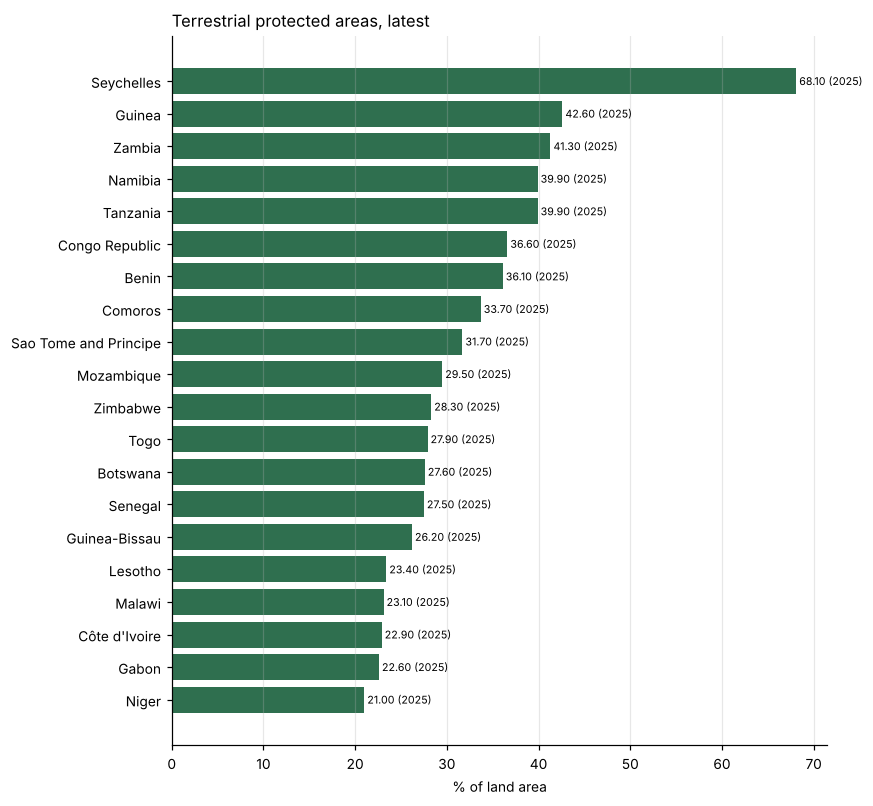

Countries at or above the 30% (30 by 30) target: 9 of 54


In [4]:
if "E05" in panel:
    pa = latest("E05", max_age=10)
    display(pa.head(10))
    barh(pa, "value", "Terrestrial protected areas, latest", "% of land area", "protected areas.png", n=20, color=GREEN)
    print(f"Countries at or above the 30% (30 by 30) target: {(pa['value'] >= 30).sum()} of {len(pa)}")

**Only 9 of 54 countries protect 30% or more of their land (the 30 by 30 target).**

Seychelles (68%), Guinea (43%), Zambia (41%), Namibia and Tanzania (40% each) lead.

## 4. Forest loss and species status (H2)

H2: relative tree cover loss vs Red List Index change, Spearman rho = 0.08 (p = 0.567), n = 54


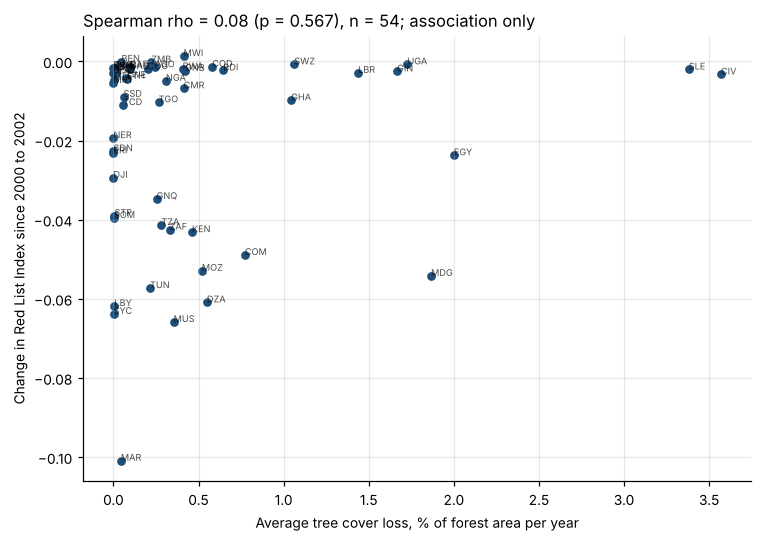

In [5]:
if has("X02", "E08"):
    loss = afp[afp["year"].between(2001, 2022)].groupby("iso3")["X02"].mean()
    d = pd.DataFrame({"relative_loss": loss, "rli_change": rli.set_index(rli.index)["abs_change"]}).dropna()
    rho, p = stats.spearmanr(d["relative_loss"], d["rli_change"])
    fig, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(d["relative_loss"], d["rli_change"], color=BLUE, s=22)
    for iso, r in d.iterrows():
        ax.annotate(iso, (r["relative_loss"], r["rli_change"]), fontsize=6, alpha=0.7)
    print(f"H2: relative tree cover loss vs Red List Index change, Spearman rho = {rho:.2f} (p = {p:.3f}), n = {len(d)}")
    ax.set_xlabel("Average tree cover loss, % of forest area per year"); ax.set_ylabel("Change in Red List Index since 2000 to 2002")
    ax.set_title(f"Spearman rho = {rho:.2f} (p = {p:.3f}), n = {len(d)}; association only", loc="left")
    fig.tight_layout(); fig.savefig(OUT / "forest loss vs red list.png", dpi=150); plt.show()

**H2 not supported: relative tree cover loss is not associated with Red List Index change across countries (rho = 0.08, p = 0.57, n = 54).**

The Red List Index is driven largely by birds and mammals and by island endemics, so it may not pick up forest-loss pressure on mainland species.

## 5. Protected areas and Red List change (descriptive only)

In [6]:
if has("E05", "E08"):
    d2 = pd.DataFrame({"protected_pct": latest("E05", max_age=10).set_index("iso3")["value"], "rli_change": rli["abs_change"]}).dropna()
    d2["group"] = pd.qcut(d2["protected_pct"], 3, labels=["low protection", "middle", "high protection"])
    display(d2.groupby("group")["rli_change"].describe()[["count", "mean", "50%"]])

,count,mean,50%
group,,,
low protection,18.000,-0.029,-0.023
middle,18.000,-0.013,-0.006
high protection,18.000,-0.015,-0.003


**Countries with low protection saw the largest median Red List decline (-0.023), against -0.006 and -0.003 in the middle and high groups.**

This is descriptive only. Protection is designation, not effectiveness, and it may be placed where species are already secure.

## 6. Save tables

In [7]:
save_excel("biodiversity results.xlsx", {**({"Red List change": rli} if "rli" in globals() else {}),
                                         **({"Threatened snapshot": snap} if "snap" in globals() else {}),
                                         **({"Protected areas": pa.set_index("iso3")} if "pa" in globals() else {})})

['biodiversity results.xlsx',
 'forest loss vs red list.png',
 'protected areas.png',
 'red list index lowest.png',
 'red list index trend.png']

## What I found

- **Biodiversity is declining almost everywhere (H1 supported):** the Red List Index fell in 98% of countries.
- **Islands are the hotspots:** Mauritius, Seychelles, Sao Tome and Principe, Madagascar and Comoros have the most threatened species.
- **Protection targets are far off:** only 9 of 54 countries meet 30 by 30.
- **Forest loss does not explain Red List change across countries (H2 not supported).** The index is not sensitive enough to mainland forest pressure, so it is a weak tool for this test.

**Why it matters for finance:** nature-related disclosure (TNFD) and biodiversity credits are reaching African markets. The data shows that island states and the Congo Basin carry the greatest biodiversity exposure, but national indices are too coarse for asset-level decisions. Site-level data will be needed for credible nature-linked finance.